# OOF error and probability analysis

This notebook audits the selected CatBoost candidate `expert_without_cat11_v22` using its saved **out-of-fold** (OOF) probabilities. It does not train or calibrate a model. The positive class is reported as `target=1`; operational claim-decision semantics need separate validation before any automated triage policy.

Questions: Are probabilities reliable? Where are errors concentrated? How do illustrative thresholds change false positives and false negatives? Do technical subgroups show different loss? Log Loss remains the primary competition metric.

## GitHub references and method

- [dc_tabeval's BNP dataset implementation](https://github.com/atschalz/dc_tabeval/blob/main/datasets.py) and [model implementations](https://github.com/atschalz/dc_tabeval/blob/main/models.py) include this competition and a CatBoost benchmark. They motivate the dataset and model comparison, not the calibration calculations below.
- [Another BNP competition implementation](https://github.com/joseluisjorgesosa/Kaggle_InsuranceClaimsCompetition) describes the required output as a probability between 0 and 1. Its modeling choices are background context, not validation of this project's results.
- [CatBoost's classification example](https://github.com/catboost/catboost/blob/master/catboost/docs/en/concepts/python-quickstart.md) shows `predict_proba` for binary classification.
- [scikit-learn's calibration guide](https://github.com/scikit-learn/scikit-learn/blob/main/doc/modules/calibration.rst) defines a reliability diagram as observed positive frequency versus mean predicted probability. It also explains why Log Loss/Brier combine calibration and discrimination, and why a fitted calibrator needs independent data. The [plotting example](https://github.com/scikit-learn/scikit-learn/blob/main/examples/calibration/plot_calibration_curve.py) motivates plotting probability counts alongside reliability.
- [The scikit-learn calibration-metrics discussion](https://github.com/scikit-learn/scikit-learn/discussions/21785) describes ECE and alternative binning choices. Here ECE is computed for the binary positive-class probability, without importing another package.

We use ten **fixed-width** probability bins so empty regions and sample counts remain visible. The count-weighted absolute bin gap (ECE) is descriptive and depends on binning; it is not a replacement for Log Loss. All threshold results are exploratory; no threshold is fitted or selected here.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src').is_dir():
    raise FileNotFoundError('Run this notebook from the project root or notebooks directory')
sys.path.insert(0, str(PROJECT_ROOT))

from src.models.diagnostics import (
    calibration_bins, expected_calibration_error, highest_loss_cases,
    segment_summary, threshold_summary, validate_oof_predictions,
)
from src.models.metrics import binary_probability_metrics

SEED = 42
EXPERIMENT_NAME = 'expert_without_cat11_v22'
EXPERIMENT_DIR = PROJECT_ROOT / 'reports' / 'experiments' / EXPERIMENT_NAME
METRICS_DIR = PROJECT_ROOT / 'reports' / 'metrics'
FIGURES_DIR = PROJECT_ROOT / 'reports' / 'figures'
METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 30)

## 1. Load and validate OOF predictions

Each training claim must have one prediction from a model that did not train on that claim. We also verify row alignment with the saved training IDs and labels, and reproduce the published metrics.

In [2]:
oof = pd.read_parquet(EXPERIMENT_DIR / 'oof_predictions.parquet')
training_metadata = json.loads((EXPERIMENT_DIR / 'training_metadata.json').read_text(encoding='utf-8'))
manifest = json.loads((PROJECT_ROOT / 'data' / 'processed' / 'feature_manifest.json').read_text(encoding='utf-8'))
train_ids = pd.read_parquet(PROJECT_ROOT / 'data' / 'processed' / 'train_ids.parquet').iloc[:, 0]
y_train = pd.read_parquet(PROJECT_ROOT / 'data' / 'processed' / 'y_train.parquet').iloc[:, 0]
validate_oof_predictions(oof)
assert training_metadata['feature_set'] == EXPERIMENT_NAME
assert training_metadata['feature_count'] == 247
assert len(oof) == len(train_ids) == len(y_train)
assert np.array_equal(oof['ID'].to_numpy(), train_ids.to_numpy())
assert np.array_equal(oof['target'].to_numpy(), y_train.to_numpy())
assert sorted(oof['fold'].unique().tolist()) == list(range(1, training_metadata['cross_validation']['n_splits'] + 1))

metrics = binary_probability_metrics(oof['target'], oof['catboost_probability'])
recorded = pd.read_csv(EXPERIMENT_DIR / 'overall_metrics.csv')
recorded_catboost = recorded.loc[recorded['model'].eq('catboost')].iloc[0]
for name, value in metrics.items():
    assert np.isclose(value, recorded_catboost[name], atol=1e-12, rtol=0), name
print(f'OOF rows: {len(oof):,}; unique IDs: {oof.ID.nunique():,}; folds: {oof.fold.nunique()}')
print(f'Positive rate: {oof.target.mean():.4f}; mean predicted probability: {oof.catboost_probability.mean():.4f}')
display(pd.DataFrame([metrics]).round(6))

OOF rows: 114,321; unique IDs: 114,321; folds: 5
Positive rate: 0.7612; mean predicted probability: 0.7609


,log_loss,roc_auc,average_precision,brier_score
0,0.438446,0.791097,0.920712,0.142246


## 2. Reliability of predicted probabilities

For a well-calibrated model, the observed `target=1` rate in each sufficiently populated bin should be near its mean predicted probability. Counts matter: a large gap in a tiny bin is less informative than a persistent gap in populous bins.

,bin,lower,upper,count,positive_count,mean_probability,observed_rate,absolute_gap
0,0,0.0,0.1,1380,49,0.0578,0.0355,0.0223
1,1,0.1,0.2,1434,187,0.1492,0.1304,0.0188
2,2,0.2,0.3,1349,291,0.2493,0.2157,0.0336
3,3,0.3,0.4,2020,725,0.3553,0.3589,0.0036
4,4,0.4,0.5,4374,2012,0.4556,0.4600,0.0044
5,5,0.5,0.6,9065,5075,0.5553,0.5598,0.0046
6,6,0.6,0.7,15802,10317,0.6535,0.6529,0.0006
7,7,0.7,0.8,20970,15677,0.7514,0.7476,0.0038
8,8,0.8,0.9,25423,21599,0.8520,0.8496,0.0025
9,9,0.9,1.0,32504,31089,0.9497,0.9565,0.0068


Ten-bin ECE (descriptive): 0.0048


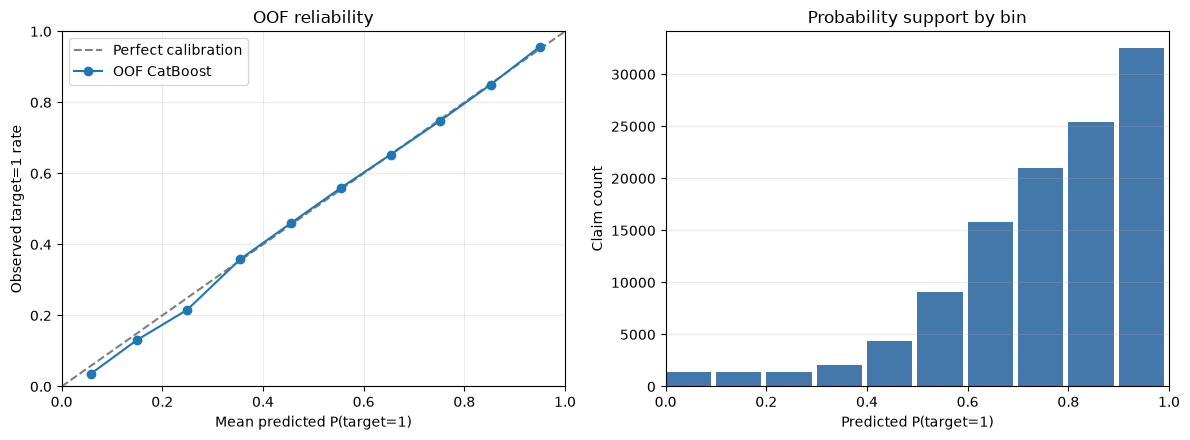

In [3]:
bins = calibration_bins(oof['target'], oof['catboost_probability'], n_bins=10)
ece = expected_calibration_error(bins)
bins.to_csv(METRICS_DIR / 'oof_calibration_bins.csv', index=False)
display(bins.round(4))
print(f'Ten-bin ECE (descriptive): {ece:.4f}')

occupied = bins.loc[bins['count'].gt(0)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
axes[0].plot(occupied['mean_probability'], occupied['observed_rate'], 'o-', label='OOF CatBoost')
axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean predicted P(target=1)', ylabel='Observed target=1 rate', title='OOF reliability')
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].bar(bins['lower'], bins['count'], width=0.09, align='edge', color='#4477aa')
axes[1].set(xlim=(0, 1), xlabel='Predicted P(target=1)', ylabel='Claim count', title='Probability support by bin')
axes[1].grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'oof_reliability.png', dpi=160, bbox_inches='tight')
plt.show()

## 3. Illustrative operating points

A threshold converts probabilities into class decisions. The table shows how many `target=1` cases would be flagged and the associated error counts. Because no business cost matrix or decision policy has been supplied, these are **examples**, not a chosen threshold. Tuning a threshold on these same OOF rows and then reporting its OOF performance would be optimistic.

In [4]:
thresholds = threshold_summary(oof['target'], oof['catboost_probability'], [0.3, 0.5, 0.7, 0.8, 0.9, 0.95])
thresholds.to_csv(METRICS_DIR / 'oof_threshold_scenarios.csv', index=False)
display(thresholds.round(4))

,threshold,predicted_positive,predicted_positive_share,true_positive,false_positive,true_negative,false_negative,precision_class_1,recall_class_1,false_positive_rate,specificity
0,0.30,110158,0.9636,86494,23664,3636,527,0.7852,0.9939,0.8668,0.1332
1,0.50,103764,0.9077,83757,20007,7293,3264,0.8072,0.9625,0.7329,0.2671
2,0.70,78897,0.6901,68365,10532,16768,18656,0.8665,0.7856,0.3858,0.6142
3,0.80,57927,0.5067,52688,5239,22061,34333,0.9096,0.6055,0.1919,0.8081
4,0.90,32504,0.2843,31089,1415,25885,55932,0.9565,0.3573,0.0518,0.9482
5,0.95,16542,0.1447,16220,322,26978,70801,0.9805,0.1864,0.0118,0.9882


## 4. Largest errors and technical subgroups

Row Log Loss ranks confident mistakes without choosing a classification threshold. Because feature meanings are anonymized, subgroup checks use only technical proxies: missingness among the 12 selected numerical features and frequency of encoded `v22` categories. These are diagnostic slices, not demographic or business fairness groups. `v22` frequency uses only unlabeled training feature values and is not passed back into model training.

In [5]:
worst_cases = highest_loss_cases(oof, top_n=50)
worst_cases.to_csv(METRICS_DIR / 'oof_highest_loss_cases.csv', index=False)
print('Largest OOF row losses:')
display(worst_cases.head(10).round(5))

numeric_names = [name for name, origin in manifest['feature_origin'].items() if origin == 'original_numerical']
assert len(numeric_names) == 12
profile = pd.read_parquet(PROJECT_ROOT / 'data' / 'processed' / 'X_train_expert.parquet', columns=[*numeric_names, 'cat1__v22'])
assert len(profile) == len(oof) and profile.index.equals(oof.index)
missing_count = profile[numeric_names].isna().sum(axis=1)
missing_segment = pd.Series(np.where(missing_count.eq(0), 'no_numeric_missing', 'numeric_missing'), index=oof.index)
v22_frequency = profile['cat1__v22'].map(profile['cat1__v22'].value_counts())
frequency_segment = pd.Series(pd.cut(v22_frequency, bins=[0, 1, 5, 20, np.inf], labels=['singleton', '2-5', '6-20', '21+']), index=oof.index)
assert not frequency_segment.isna().any()

missing_results = segment_summary(oof, missing_segment)
missing_results.insert(0, 'analysis_group', 'numerical_missingness')
frequency_results = segment_summary(oof, frequency_segment)
frequency_order = ['singleton', '2-5', '6-20', '21+']
frequency_results['segment'] = pd.Categorical(frequency_results['segment'], categories=frequency_order, ordered=True)
frequency_results = frequency_results.sort_values('segment').reset_index(drop=True)
frequency_results['segment'] = frequency_results['segment'].astype(str)
frequency_results.insert(0, 'analysis_group', 'v22_train_frequency')
subgroups = pd.concat([missing_results, frequency_results], ignore_index=True)
assert subgroups['rows'].gt(0).all()
subgroups.to_csv(METRICS_DIR / 'oof_technical_subgroups.csv', index=False)
display(subgroups.round(5))

Largest OOF row losses:


,ID,target,fold,catboost_probability,row_log_loss
0,121248,1,4,0.00690,4.97611
1,171656,0,5,0.99237,4.87602
2,1885,0,3,0.99138,4.75383
3,100729,0,2,0.99132,4.74713
4,135154,0,5,0.98991,4.59612
5,110282,0,4,0.98939,4.54587
6,87527,0,5,0.98903,4.51247
7,137499,1,2,0.01105,4.50539
8,134535,0,5,0.98793,4.41708
9,38469,0,3,0.98752,4.38339


,analysis_group,segment,rows,observed_rate,mean_probability,log_loss,roc_auc,average_precision,brier_score
0,numerical_missingness,no_numeric_missing,113684,0.76059,0.76025,0.43928,0.79070,0.92029,0.14256
1,numerical_missingness,numeric_missing,637,0.86970,0.87412,0.28907,0.83430,0.96428,0.08640
2,v22_train_frequency,singleton,7239,0.75452,0.75833,0.47787,0.74738,0.89509,0.15620
3,v22_train_frequency,2-5,20654,0.77297,0.77512,0.41667,0.80562,0.93152,0.13439
4,v22_train_frequency,6-20,29202,0.77406,0.76943,0.41603,0.80361,0.93042,0.13355
5,v22_train_frequency,21+,57226,0.75123,0.75172,0.45276,0.78425,0.91375,0.14776


## 5. Reproducible summary and interpretation

The JSON below records the checked candidate, metrics, probability calibration summary and output paths. No calibrator or operating threshold is fitted. Any later recalibration or threshold choice must have its own validation design so its reported performance is not estimated on the same labels used to choose it.

In [6]:
summary = {
    'feature_set': EXPERIMENT_NAME,
    'oof_rows': int(len(oof)),
    'folds': int(oof['fold'].nunique()),
    'observed_positive_rate': float(oof['target'].mean()),
    'mean_predicted_probability': float(oof['catboost_probability'].mean()),
    'metrics': metrics,
    'calibration': {
        'method': '10 fixed-width bins',
        'expected_calibration_error': ece,
        'occupied_bins': int(bins['count'].gt(0).sum()),
        'largest_occupied_bin_gap': float(occupied['absolute_gap'].max()),
    },
    'artifacts': [
        'reports/metrics/oof_calibration_bins.csv',
        'reports/metrics/oof_threshold_scenarios.csv',
        'reports/metrics/oof_highest_loss_cases.csv',
        'reports/metrics/oof_technical_subgroups.csv',
        'reports/figures/oof_reliability.png',
    ],
    'source_experiment': 'reports/experiments/expert_without_cat11_v22',
    'validation_scope': 'CatBoost OOF; unsupervised feature mappings fitted once on full training features before CV',
    'decision_threshold_selected': False,
    'calibrator_fitted': False,
}
summary_path = METRICS_DIR / 'oof_diagnostics_summary.json'
summary_path.write_text(json.dumps(summary, indent=2) + '\n', encoding='utf-8')
assert json.loads(summary_path.read_text(encoding='utf-8')) == summary
print(json.dumps({key: summary[key] for key in ['oof_rows', 'metrics', 'calibration']}, indent=2))
print('Validation passed; diagnostic artifacts saved.')

{
  "oof_rows": 114321,
  "metrics": {
    "log_loss": 0.4384459092278412,
    "roc_auc": 0.7910969719615909,
    "average_precision": 0.9207120094893335,
    "brier_score": 0.1422462100319219
  },
  "calibration": {
    "method": "10 fixed-width bins",
    "expected_calibration_error": 0.004757344732126146,
    "occupied_bins": 10,
    "largest_occupied_bin_gap": 0.03359902887985999
  }
}
Validation passed; diagnostic artifacts saved.


## Findings for this saved run

- Overall mean predicted probability (0.7609) is close to the observed positive rate (0.7612). Ten-bin ECE is 0.0048. The largest absolute bin gap is 0.0336 in the 0.2–0.3 bin (1,349 rows), so good aggregate calibration does not mean every probability range is equally reliable.
- At the illustrative threshold 0.9, 32,504 rows are labeled class 1; 1,415 of these have `target=0` (precision 0.9565), and class-1 recall is 0.3573. This is not an approved triage threshold.
- Rows whose encoded `v22` category occurs once in training (7,239 rows) have OOF Log Loss 0.4779, above the overall 0.4384. This slice merits monitoring, but anonymized features do not support a business or fairness interpretation.
- OOF status applies to CatBoost fitting. The unsupervised feature mappings were fitted once on all training features before the CV split, so these scores are not a fully nested preprocessing evaluation. Target encoding was disabled. The candidate was also chosen from four runs using these OOF labels, which can make its reported score optimistic.

These observations support reviewing rare-category behavior and collecting decision costs before considering calibration or a triage threshold.